In [2]:
import pandas as pd
df = pd.read_csv("C:/Users/kaila/OneDrive - National Institute of Technology/Desktop/DATA PROJECTS/ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.shapes

AttributeError: 'DataFrame' object has no attribute 'shapes'

In [4]:
df.shape

(10000, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [6]:
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [7]:
df["Machine failure"].value_counts()   

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [9]:
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicates: 0


In [10]:
df = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure",
})
df.columns

Index(['UDI', 'Product ID', 'Type', 'air_temp', 'process_temp', 'rpm',
       'torque', 'tool_wear', 'machine_failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

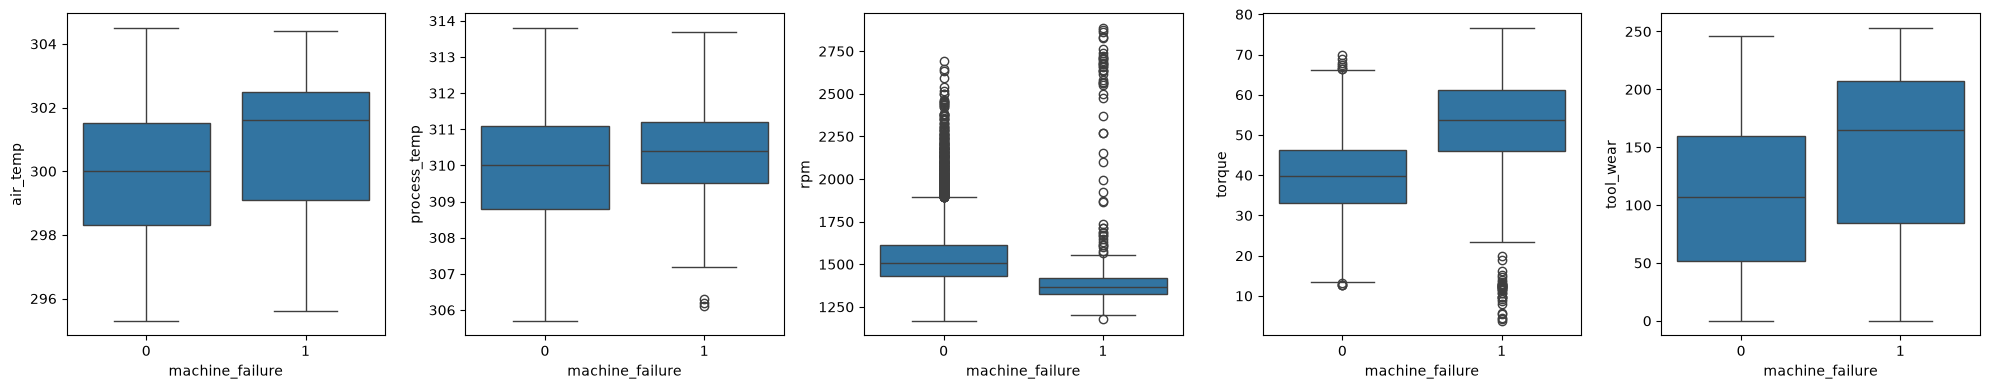

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="machine_failure", y=col, ax=ax)
plt.tight_layout()
plt.show()

Type
H    0.020937
L    0.039167
M    0.027694
Name: machine_failure, dtype: float64


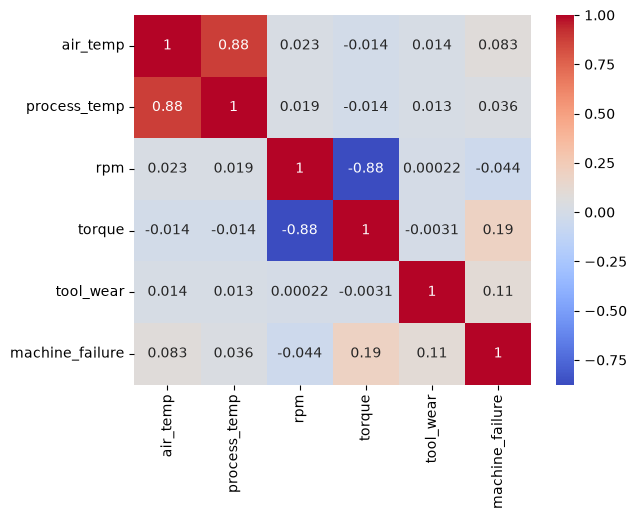

In [12]:
print(df.groupby("Type")["machine_failure"].mean())

sns.heatmap(df[features + ["machine_failure"]].corr(), annot=True, cmap="coolwarm")
plt.show()

What the boxplots show

Torque: failures have a much higher median (about 54 Nm versus about 40), and there is also a cluster of very low-torque failures.
RPM: failures run at lower speeds (median about 1,370 versus about 1,500), with a few very high-speed failures.
Tool wear: failures tend to have more wear, with a median around 165 min versus about 105.
Air and process temperature: only a slight shift, so they are weaker signals on their own.


What the heatmap shows

air_temp and process_temp are strongly correlated (0.88), and so are rpm and torque (-0.88). This matters for Logistic Regression, whose coefficients get unstable with correlated inputs. Tree models don’t mind.
No single feature correlates strongly with failure (the highest is torque at 0.19). This doesn’t mean the features are useless. Correlation only measures straight-line relationships, and the boxplots show failures at both low and high extremes (torque and rpm both have outliers on both sides). Tree-based models can capture this kind of pattern, which is a good reason to compare a linear model with a Random Forest.

In [14]:
import numpy as np

def add_features(d):
    d = d.copy()
    d["temp_diff"] = d["process_temp"] - d["air_temp"]
    d["power_w"] = d["torque"] * d["rpm"] * 2 * np.pi / 60   # watts
    d["wear_torque"] = d["tool_wear"] * d["torque"]
    return d

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

rf_fe = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
)
rf_fe.fit(X_train_fe, y_train)

pred_fe = rf_fe.predict(X_test_fe)
proba_fe = rf_fe.predict_proba(X_test_fe)[:, 1]
print(classification_report(y_test, pred_fe, digits=3))
print("PR-AUC:", average_precision_score(y_test, proba_fe))

NameError: name 'X_train' is not defined

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

# 1. Load and rename
df = pd.read_csv("C:/Users/kaila/OneDrive - National Institute of Technology/Desktop/DATA PROJECTS/ai4i2020.csv")
df = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure",
})

# 2. Features and split (no UDI, Product ID or the 5 failure-type columns)
features = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]
X = df[features]
y = df["machine_failure"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Engineered features
def add_features(d):
    d = d.copy()
    d["temp_diff"] = d["process_temp"] - d["air_temp"]
    d["power_w"] = d["torque"] * d["rpm"] * 2 * np.pi / 60
    d["wear_torque"] = d["tool_wear"] * d["torque"]
    return d

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

# 4. Train and evaluate the three models
def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred, digits=3))
    print(confusion_matrix(y_test, pred))
    print("PR-AUC:", round(average_precision_score(y_test, proba), 3))

evaluate("Logistic Regression",
         make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
         X_train, X_test)
evaluate("Random Forest",
         RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
         X_train, X_test)
evaluate("Random Forest + engineered features",
         RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
         X_train_fe, X_test_fe)


===== Logistic Regression =====
              precision    recall  f1-score   support

           0      0.993     0.820     0.899      1932
           1      0.141     0.838     0.242        68

    accuracy                          0.821      2000
   macro avg      0.567     0.829     0.570      2000
weighted avg      0.964     0.821     0.876      2000

[[1585  347]
 [  11   57]]
PR-AUC: 0.403

===== Random Forest =====
              precision    recall  f1-score   support

           0      0.990     0.991     0.990      1932
           1      0.727     0.706     0.716        68

    accuracy                          0.981      2000
   macro avg      0.858     0.848     0.853      2000
weighted avg      0.981     0.981     0.981      2000

[[1914   18]
 [  20   48]]
PR-AUC: 0.774

===== Random Forest + engineered features =====
              precision    recall  f1-score   support

           0      0.994     0.996     0.995      1932
           1      0.889     0.824     0.855   

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["precision", "recall", "f1", "average_precision"]

def cv_report(name, model, X):
    s = cross_validate(model, X, y_train, cv=cv, scoring=metrics)
    print(name)
    for m in metrics:
        print(f"  {m}: {s['test_' + m].mean():.3f} +/- {s['test_' + m].std():.3f}")

make_rf = lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
cv_report("RF", make_rf(), X_train)
cv_report("RF + engineered features", make_rf(), X_train_fe)

RF
  precision: 0.691 +/- 0.049
  recall: 0.672 +/- 0.049
  f1: 0.680 +/- 0.044
  average_precision: 0.738 +/- 0.050
RF + engineered features
  precision: 0.847 +/- 0.017
  recall: 0.801 +/- 0.054
  f1: 0.823 +/- 0.036
  average_precision: 0.867 +/- 0.030


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

proba_cv = cross_val_predict(make_rf(), X_train_fe, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, proba_cv)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1[:-1])]
print("Best threshold:", round(float(best_thr), 3))

# evaluate ONCE on the test set with that threshold
final_model = make_rf().fit(X_train_fe, y_train)
proba_test = final_model.predict_proba(X_test_fe)[:, 1]
print(classification_report(y_test, (proba_test >= best_thr).astype(int), digits=3))
print(confusion_matrix(y_test, (proba_test >= best_thr).astype(int)))

Best threshold: 0.567
              precision    recall  f1-score   support

           0      0.993     0.997     0.995      1932
           1      0.900     0.794     0.844        68

    accuracy                          0.990      2000
   macro avg      0.946     0.896     0.919      2000
weighted avg      0.990     0.990     0.990      2000

[[1926    6]
 [  14   54]]


: 